# Retail-sales-forcasting

## Import the required libraries

In [2]:
!pip install streamlit

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.2/11.2 MB 110.2 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.4/11.4 MB 81.2 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [streamlit]


In [21]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
import statsmodels
import xgboost
import streamlit

print("All libraries imported successfully!")

All libraries imported successfully!


## Load the dataset


In [6]:
import pandas as pd

# Load the datasets
df = pd.read_csv('/content/train.csv')

print(f"Train dataset shape: {df.shape}")
# print(f"Test dataset shape: {test_df.shape}")

Train dataset shape: (913000, 4)


In [7]:
# Display the first few rows of the training dataset
display(df.head())

,date,store,item,sales
0,2013-01-01,1,1,13
1,2013-01-02,1,1,11
2,2013-01-03,1,1,14
3,2013-01-04,1,1,13
4,2013-01-05,1,1,10


## Understand the dataset structure

In [8]:
print("Dataset Shape:", df.shape)

print("Number of Rows:", df.shape[0])
print("Number of Columns:", df.shape[1])

Dataset Shape: (913000, 4)
Number of Rows: 913000
Number of Columns: 4


In [9]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 913000 entries, 0 to 912999
Data columns (total 4 columns):
 #   Column  Non-Null Count   Dtype 
---  ------  --------------   ----- 
 0   date    913000 non-null  object
 1   store   913000 non-null  int64 
 2   item    913000 non-null  int64 
 3   sales   913000 non-null  int64 
dtypes: int64(3), object(1)
memory usage: 27.9+ MB


In [10]:
df["date"] = pd.to_datetime(
    df["date"],
    errors="coerce"
)

df.dtypes

,0
date,datetime64[ns]
store,int64
item,int64
sales,int64


In [11]:
df.describe()

,date,store,item,sales
count,913000,913000.000000,913000.000000,913000.000000
mean,2015-07-02 11:59:59.999999744,5.500000,25.500000,52.250287
min,2013-01-01 00:00:00,1.000000,1.000000,0.000000
25%,2014-04-02 00:00:00,3.000000,13.000000,30.000000
50%,2015-07-02 12:00:00,5.500000,25.500000,47.000000
75%,2016-10-01 00:00:00,8.000000,38.000000,70.000000
max,2017-12-31 00:00:00,10.000000,50.000000,231.000000
std,NaN,2.872283,14.430878,28.801144


In [12]:
print("Missing Values:")
print(df.isnull().sum())

Missing Values:
date     0
store    0
item     0
sales    0
dtype: int64


In [13]:
print(
    "Duplicate Records:",
    df.duplicated().sum()
)

Duplicate Records: 0


In [22]:
print(
    "Duplicate Date-Store-Item combinations:",
    df.duplicated(
        subset=["date", "store", "item"]
    ).sum()
)

Duplicate Date-Store-Item combinations: 0


## Understand unique stores and products

In [23]:
print("Unique Stores:", df["store"].nunique())

print("Unique Products:", df["item"].nunique())

print("Unique Dates:", df["date"].nunique())

Unique Stores: 10
Unique Products: 50
Unique Dates: 1826


In [24]:
print("Stores:", sorted(df["store"].unique()))

print("Products:", sorted(df["item"].unique()))

Stores: [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10)]
Products: [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10), np.int64(11), np.int64(12), np.int64(13), np.int64(14), np.int64(15), np.int64(16), np.int64(17), np.int64(18), np.int64(19), np.int64(20), np.int64(21), np.int64(22), np.int64(23), np.int64(24), np.int64(25), np.int64(26), np.int64(27), np.int64(28), np.int64(29), np.int64(30), np.int64(31), np.int64(32), np.int64(33), np.int64(34), np.int64(35), np.int64(36), np.int64(37), np.int64(38), np.int64(39), np.int64(40), np.int64(41), np.int64(42), np.int64(43), np.int64(44), np.int64(45), np.int64(46), np.int64(47), np.int64(48), np.int64(49), np.int64(50)]


## Analyse sales over time

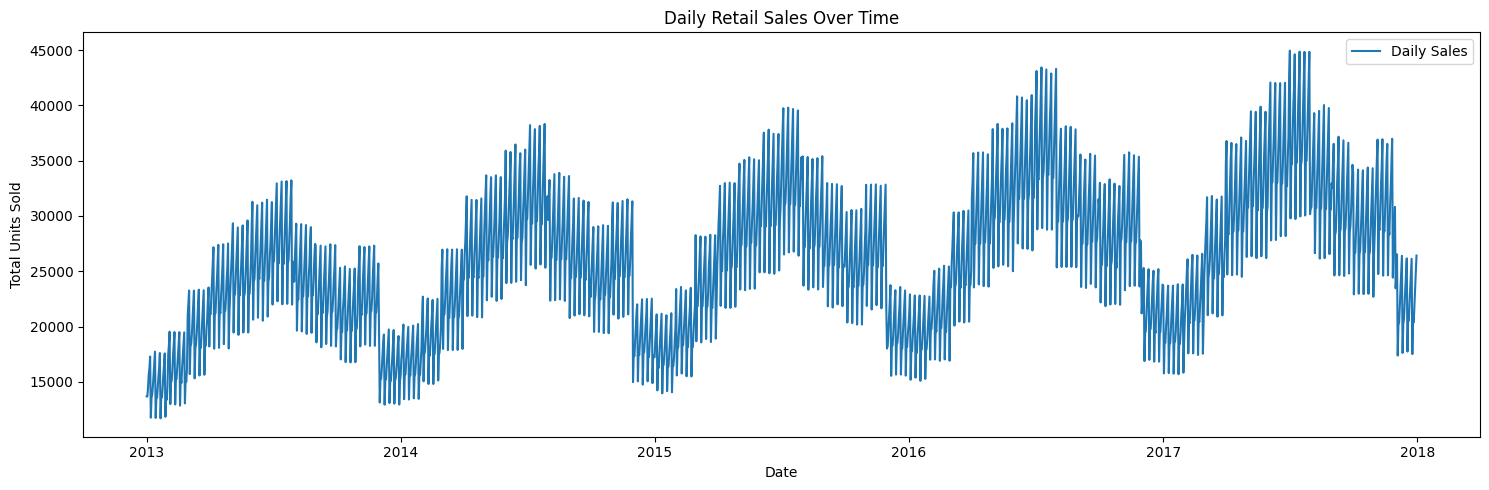

In [25]:
daily_sales = (
    df.groupby("date")["sales"]
    .sum()
    .sort_index()
)

plt.figure(figsize=(15, 5))

plt.plot(
    daily_sales.index,
    daily_sales.values,
    label="Daily Sales"
)

plt.title("Daily Retail Sales Over Time")
plt.xlabel("Date")
plt.ylabel("Total Units Sold")

plt.legend()
plt.tight_layout()
plt.show()

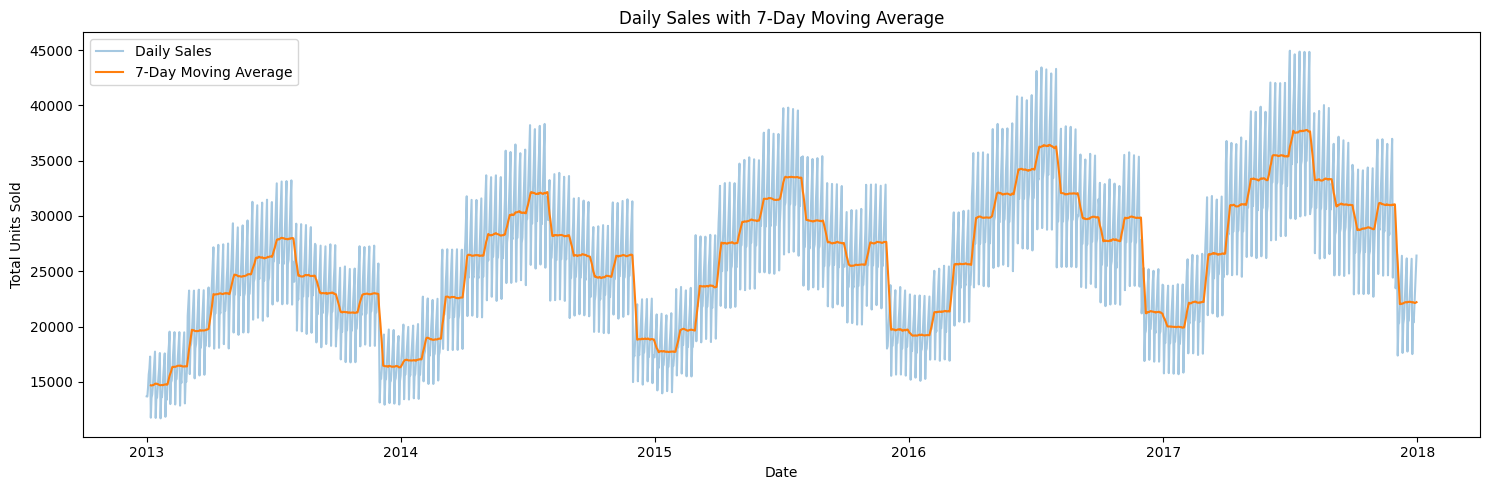

In [26]:
rolling_sales = daily_sales.rolling(
    window=7
).mean()

plt.figure(figsize=(15, 5))

plt.plot(
    daily_sales,
    alpha=0.4,
    label="Daily Sales"
)

plt.plot(
    rolling_sales,
    label="7-Day Moving Average"
)

plt.title("Daily Sales with 7-Day Moving Average")
plt.xlabel("Date")
plt.ylabel("Total Units Sold")

plt.legend()
plt.tight_layout()
plt.show()

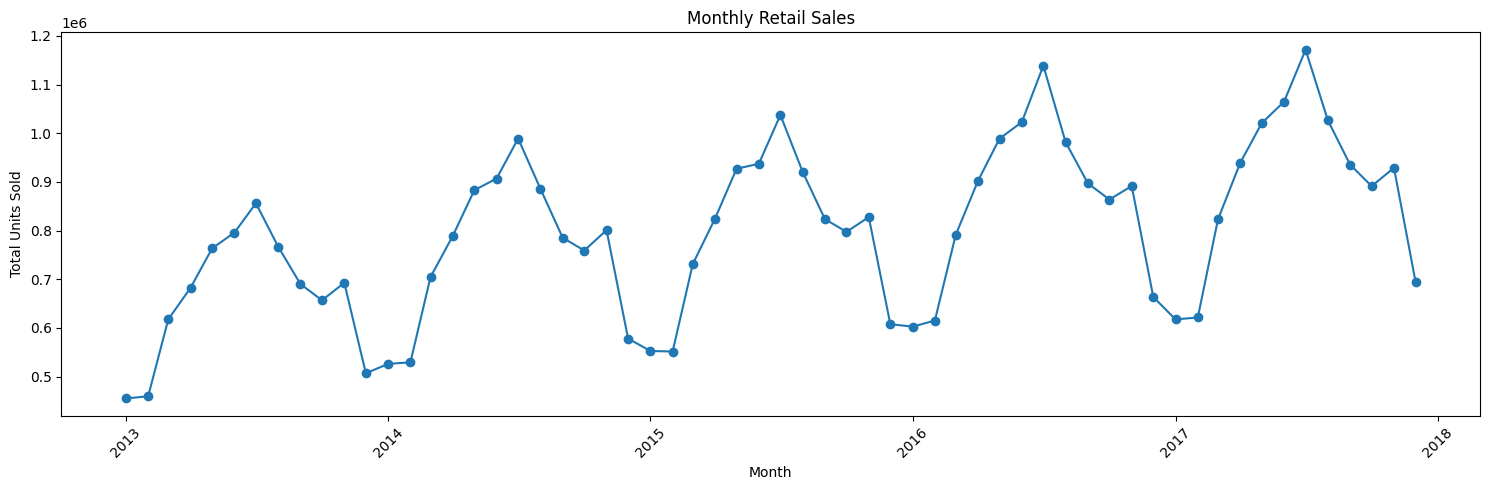

In [27]:
monthly_sales = daily_sales.resample("MS").sum()

plt.figure(figsize=(15, 5))

plt.plot(
    monthly_sales.index,
    monthly_sales.values,
    marker="o"
)

plt.title("Monthly Retail Sales")
plt.xlabel("Month")
plt.ylabel("Total Units Sold")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

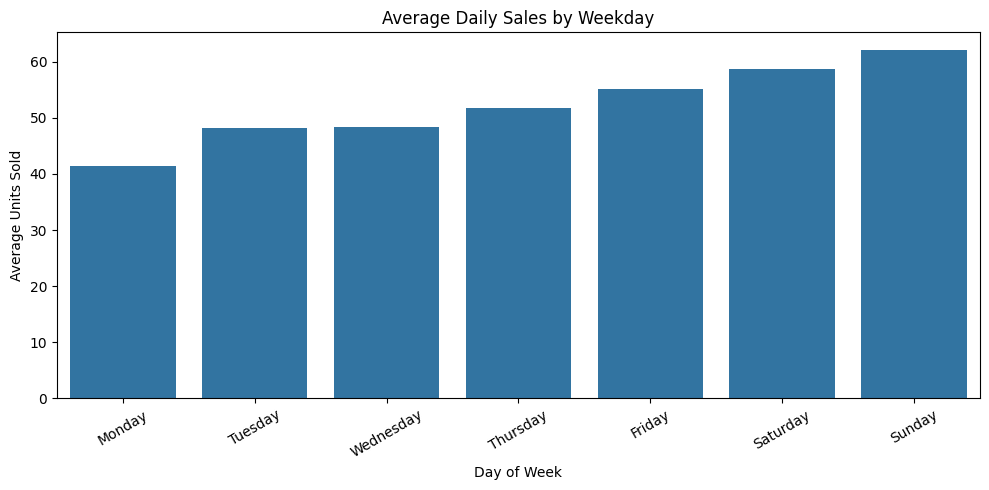

In [28]:
weekday_order = [
    "Monday", "Tuesday", "Wednesday",
    "Thursday", "Friday", "Saturday", "Sunday"
]

df["day_name"] = df["date"].dt.day_name()

weekday_sales = (
    df.groupby("day_name")["sales"]
    .mean()
    .reindex(weekday_order)
)

plt.figure(figsize=(10, 5))

sns.barplot(
    x=weekday_sales.index,
    y=weekday_sales.values
)

plt.title("Average Daily Sales by Weekday")
plt.xlabel("Day of Week")
plt.ylabel("Average Units Sold")

plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

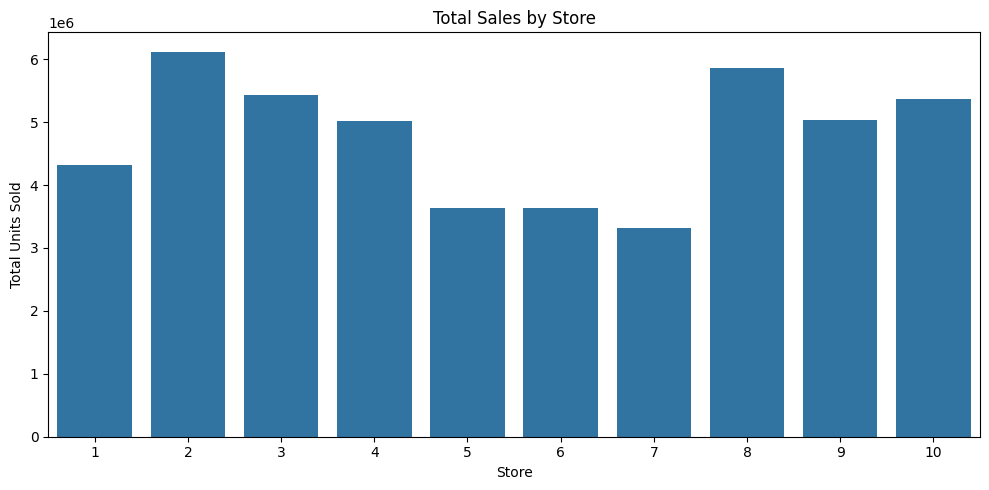

In [29]:
store_sales = (
    df.groupby("store")["sales"]
    .sum()
    .sort_values(ascending=False)
)

plt.figure(figsize=(10, 5))

sns.barplot(
    x=store_sales.index,
    y=store_sales.values
)

plt.title("Total Sales by Store")
plt.xlabel("Store")
plt.ylabel("Total Units Sold")

plt.tight_layout()
plt.show()

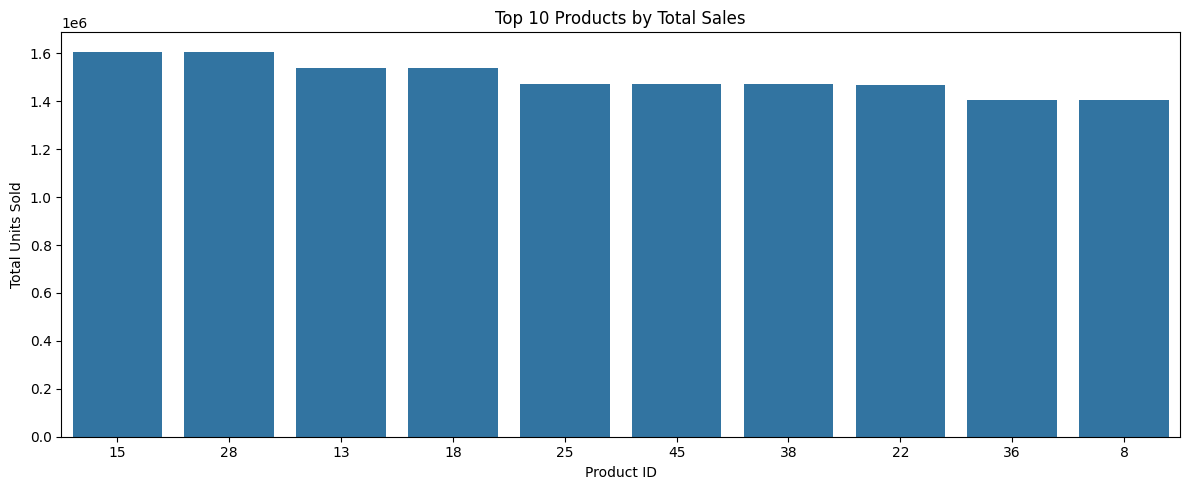

In [30]:
item_sales = (
    df.groupby("item")["sales"]
    .sum()
    .sort_values(ascending=False)
)

top_10_items = item_sales.head(10)

plt.figure(figsize=(12, 5))

sns.barplot(
    x=top_10_items.index.astype(str),
    y=top_10_items.values
)

plt.title("Top 10 Products by Total Sales")
plt.xlabel("Product ID")
plt.ylabel("Total Units Sold")

plt.tight_layout()
plt.show()

In [31]:
# Dataset quality analysis

print("Dataset Shape:", df.shape)

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Records:")
print(df.duplicated().sum())

print("\nDuplicate Date-Store-Item Records:")
print(
    df.duplicated(
        subset=["date", "store", "item"]
    ).sum()
)

print("\nUnique Stores:", df["store"].nunique())
print("Unique Products:", df["item"].nunique())

print("\nDate Range:")
print("Start:", df["date"].min())
print("End:", df["date"].max())

print("\nSales Statistics:")
print(df["sales"].describe())

Dataset Shape: (913000, 5)

Missing Values:
date        0
store       0
item        0
sales       0
day_name    0
dtype: int64

Duplicate Records:
0

Duplicate Date-Store-Item Records:
0

Unique Stores: 10
Unique Products: 50

Date Range:
Start: 2013-01-01 00:00:00
End: 2017-12-31 00:00:00

Sales Statistics:
count    913000.000000
mean         52.250287
std          28.801144
min           0.000000
25%          30.000000
50%          47.000000
75%          70.000000
max         231.000000
Name: sales, dtype: float64


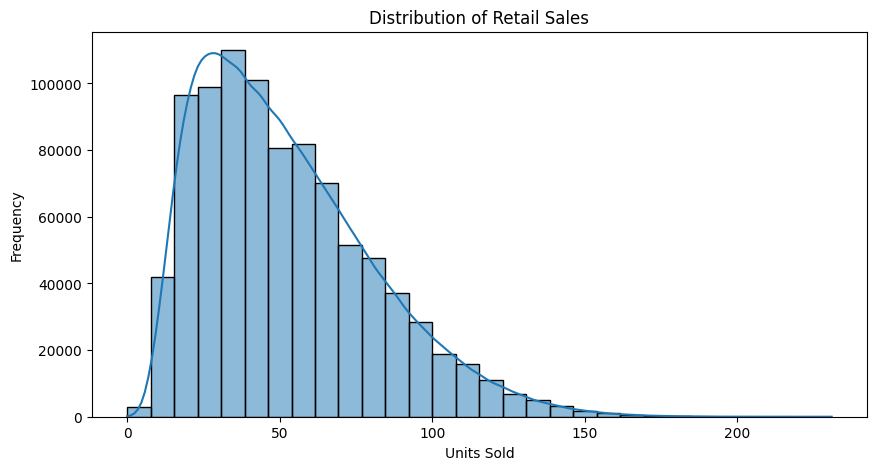

In [32]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=df,
    x="sales",
    bins=30,
    kde=True
)

plt.title("Distribution of Retail Sales")
plt.xlabel("Units Sold")
plt.ylabel("Frequency")
plt.show()

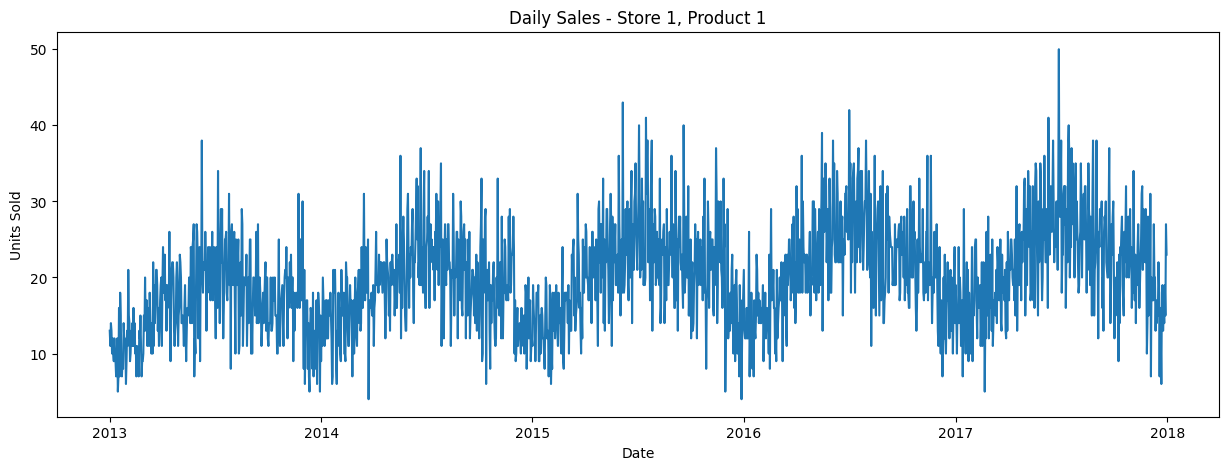

In [33]:
sample_data = df[
    (df["store"] == 1) &
    (df["item"] == 1)
].copy()

sample_data = sample_data.sort_values("date")

plt.figure(figsize=(15, 5))

plt.plot(
    sample_data["date"],
    sample_data["sales"]
)

plt.title("Daily Sales - Store 1, Product 1")
plt.xlabel("Date")
plt.ylabel("Units Sold")
plt.show()

### EDA Findings

### seasonal decomposition

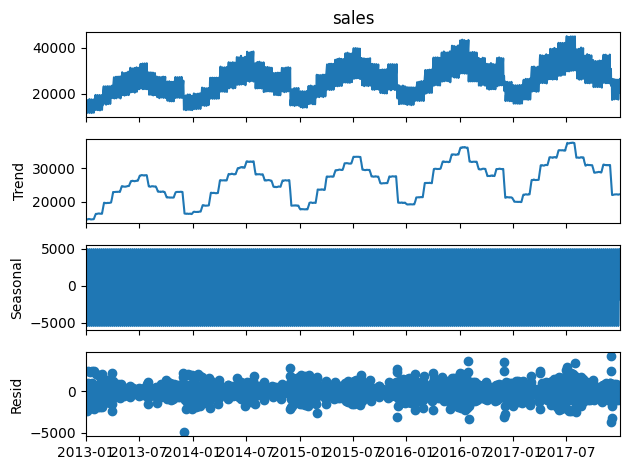

In [34]:
from statsmodels.tsa.seasonal import seasonal_decompose

# Aggregate sales by date
daily_sales = (
    df.groupby("date")["sales"]
    .sum()
    .sort_index()
)

# Perform weekly seasonal decomposition
decomposition = seasonal_decompose(
    daily_sales,
    model="additive",
    period=7
)

# Visualize components
decomposition.plot()
plt.tight_layout()
plt.show()

### sales autocorrelation

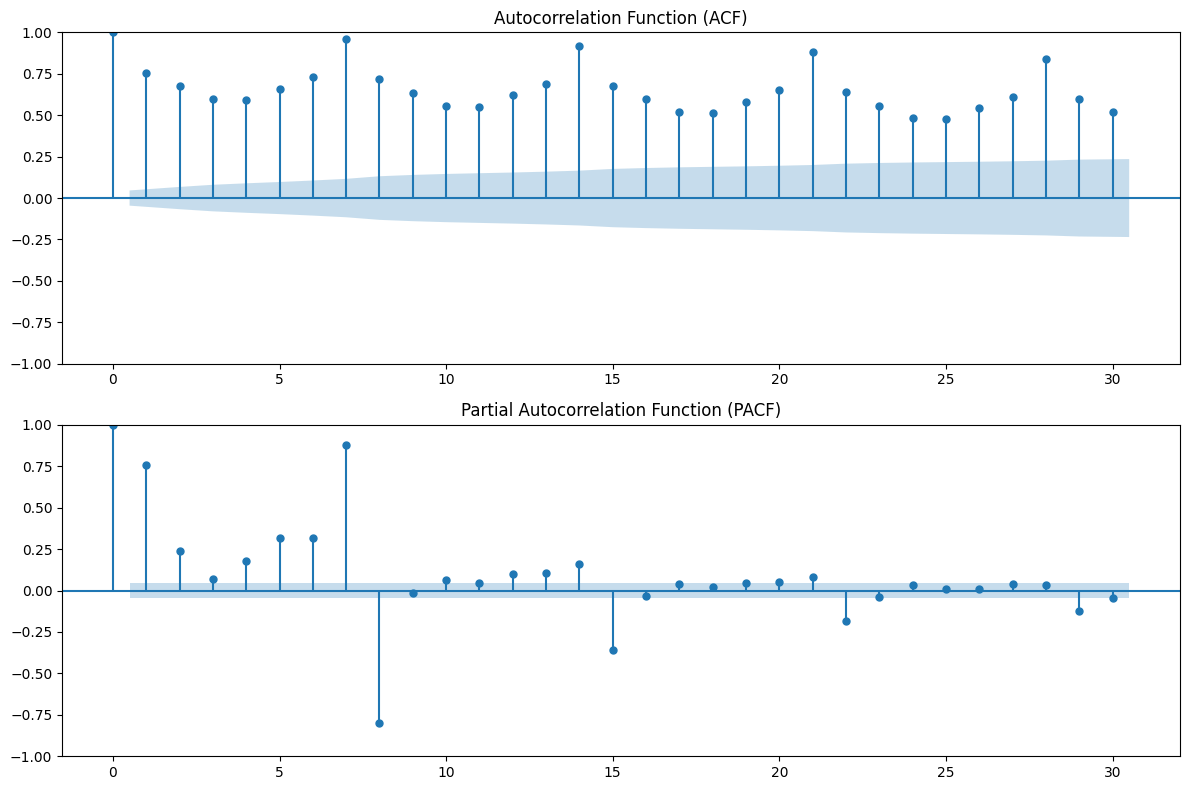

In [35]:
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

fig, axes = plt.subplots(2, 1, figsize=(12, 8))

plot_acf(daily_sales, lags=30, ax=axes[0])
axes[0].set_title("Autocorrelation Function (ACF)")

plot_pacf(daily_sales, lags=30, ax=axes[1], method="ywm")
axes[1].set_title("Partial Autocorrelation Function (PACF)")

plt.tight_layout()
plt.show()

### Check stationarity

In [36]:
from statsmodels.tsa.stattools import adfuller

adf_result = adfuller(daily_sales)

print("ADF Statistic:", adf_result[0])
print("p-value:", adf_result[1])

if adf_result[1] <= 0.05:
    print("The series is stationary.")
else:
    print("The series is non-stationary.")

ADF Statistic: -3.060244118701342
p-value: 0.02963864926884404
The series is stationary.


/tmp/ipykernel_1756/2671518968.py:3: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_result = adfuller(daily_sales)


## Data Preprocessing and Feature Engineering

### Select one store and product

In [37]:
store_id = 1
item_id = 1

sales_df = df[
    (df["store"] == store_id) &
    (df["item"] == item_id)
].copy()

sales_df = sales_df.sort_values("date")

print(sales_df.head())
print("Shape:", sales_df.shape)

        date  store  item  sales   day_name
0 2013-01-01      1     1     13    Tuesday
1 2013-01-02      1     1     11  Wednesday
2 2013-01-03      1     1     14   Thursday
3 2013-01-04      1     1     13     Friday
4 2013-01-05      1     1     10   Saturday
Shape: (1826, 5)


### Set date as the index

In [38]:
sales_df = sales_df.set_index("date")

sales_series = sales_df["sales"]

print(sales_series.head())

date
2013-01-01    13
2013-01-02    11
2013-01-03    14
2013-01-04    13
2013-01-05    10
Name: sales, dtype: int64


### Data quality validation

In [39]:
# Check duplicate dates
print("Duplicate dates:", sales_df.index.duplicated().sum())

# Check missing values
print("Missing values:\n", sales_df.isnull().sum())

# Check date range
print("Start date:", sales_df.index.min())
print("End date:", sales_df.index.max())

# Check expected daily frequency
expected_dates = pd.date_range(
    start=sales_df.index.min(),
    end=sales_df.index.max(),
    freq="D"
)

missing_dates = expected_dates.difference(sales_df.index)

print("Missing dates:", len(missing_dates))
print(missing_dates[:10])

Duplicate dates: 0
Missing values:
 store       0
item        0
sales       0
day_name    0
dtype: int64
Start date: 2013-01-01 00:00:00
End date: 2017-12-31 00:00:00
Missing dates: 0
DatetimeIndex([], dtype='datetime64[ns]', freq='D')


## Feature Engineering

### lag feature

In [40]:
features_df = sales_series.to_frame(name="sales")

# Create lag features
for lag in [1, 7, 14, 28]:
    features_df[f"lag_{lag}"] = (
        features_df["sales"].shift(lag)
    )

features_df.head(35)

,sales,lag_1,lag_7,lag_14,lag_28
date,,,,,
2013-01-01,13,NaN,NaN,NaN,NaN
2013-01-02,11,13.0,NaN,NaN,NaN
2013-01-03,14,11.0,NaN,NaN,NaN
2013-01-04,13,14.0,NaN,NaN,NaN
2013-01-05,10,13.0,NaN,NaN,NaN
2013-01-06,12,10.0,NaN,NaN,NaN
2013-01-07,10,12.0,NaN,NaN,NaN
2013-01-08,9,10.0,13.0,NaN,NaN
2013-01-09,12,9.0,11.0,NaN,NaN


### Rolling window feature

In [41]:
# Shift by one day to avoid using current-day sales
past_sales = features_df["sales"].shift(1)

features_df["rolling_mean_7"] = (
    past_sales.rolling(window=7).mean()
)

features_df["rolling_mean_14"] = (
    past_sales.rolling(window=14).mean()
)

features_df["rolling_mean_28"] = (
    past_sales.rolling(window=28).mean()
)

features_df["rolling_std_7"] = (
    past_sales.rolling(window=7).std()
)


### Data based feature

In [42]:
features_df["day_of_week"] = (
    features_df.index.dayofweek
)

features_df["month"] = (
    features_df.index.month
)

features_df["day"] = (
    features_df.index.day
)

features_df["week_of_year"] = (
    features_df.index.isocalendar().week.astype(int)
)

features_df["is_weekend"] = (
    features_df["day_of_week"] >= 5
).astype(int)

In [43]:
features_df = features_df.dropna()

print(features_df.head())
print("Feature dataset shape:", features_df.shape)

            sales  lag_1  lag_7  lag_14  lag_28  rolling_mean_7  \
date                                                              
2013-01-29      6   11.0    7.0     5.0    13.0       10.428571   
2013-01-30      9    6.0    9.0     7.0    11.0       10.285714   
2013-01-31     13    9.0    8.0    16.0    14.0       10.285714   
2013-02-01     11   13.0   14.0     7.0    13.0       11.000000   
2013-02-02     21   11.0   12.0    18.0    10.0       10.571429   

            rolling_mean_14  rolling_mean_28  rolling_std_7  day_of_week  \
date                                                                       
2013-01-29        10.642857        10.714286       2.507133            1   
2013-01-30        10.714286        10.464286       2.751623            2   
2013-01-31        10.857143        10.392857       2.751623            3   
2013-02-01        10.642857        10.357143       2.708013            4   
2013-02-02        10.928571        10.285714       2.370453            5  

## Train - Test split

In [44]:
# Forecast horizon
forecast_horizon = 30

# Determine cutoff date
cutoff_date = sales_series.index[-forecast_horizon]

# Split original time series
train_series = sales_series[
    sales_series.index < cutoff_date
]

test_series = sales_series[
    sales_series.index >= cutoff_date
]

print("Training shape:", train_series.shape)
print("Testing shape:", test_series.shape)

print("Training period:")
print(train_series.index.min(), "to", train_series.index.max())

print("\nTesting period:")
print(test_series.index.min(), "to", test_series.index.max())

Training shape: (1796,)
Testing shape: (30,)
Training period:
2013-01-01 00:00:00 to 2017-12-01 00:00:00

Testing period:
2017-12-02 00:00:00 to 2017-12-31 00:00:00


## Prepare XGBoost training features

In [45]:
xgb_train = features_df[
    features_df.index < cutoff_date
].copy()

X_train = xgb_train.drop(columns=["sales"])
y_train = xgb_train["sales"]

print("X_train:", X_train.shape)
print("y_train:", y_train.shape)

X_train: (1768, 13)
y_train: (1768,)


## Arima and Srima dataset

In [46]:
arima_train = train_series.copy()
arima_test = test_series.copy()

sarima_train = train_series.copy()
sarima_test = test_series.copy()

print("ARIMA training:", arima_train.shape)
print("ARIMA testing:", arima_test.shape)

print("SARIMA training:", sarima_train.shape)
print("SARIMA testing:", sarima_test.shape)

ARIMA training: (1796,)
ARIMA testing: (30,)
SARIMA training: (1796,)
SARIMA testing: (30,)


In [50]:
pip install statsmodels scikit-learn xgboost matplotlib pandas numpy

In [51]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.statespace.sarimax import SARIMAX

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error
)

from xgboost import XGBRegressor

## Model 1 – ARIMA implementation

In [52]:
from statsmodels.tsa.stattools import adfuller

result = adfuller(arima_train)

print("ADF Statistic:", result[0])
print("p-value:", result[1])

ADF Statistic: -3.09962593949843
p-value: 0.02658088302259682


/tmp/ipykernel_1756/2475379394.py:3: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  result = adfuller(arima_train)


In [53]:
arima_model = ARIMA(
    arima_train,
    order=(1, 1, 1)
)

arima_fitted = arima_model.fit()

print(arima_fitted.summary())

/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)


                               SARIMAX Results                                
Dep. Variable:                  sales   No. Observations:                 1796
Model:                 ARIMA(1, 1, 1)   Log Likelihood               -5569.683
Date:                Fri, 06 Nov 2026   AIC                          11145.366
Time:                        14:59:20   BIC                          11161.844
Sample:                    01-01-2013   HQIC                         11151.450
                         - 12-01-2017                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.0760      0.026      2.895      0.004       0.025       0.127
ma.L1         -0.9231      0.010    -89.839      0.000      -0.943      -0.903
sigma2        28.9895      0.886     32.736      0.0

### 30 days forecasting

In [54]:
arima_predictions = arima_fitted.forecast(
    steps=30
)

arima_predictions.index = arima_test.index

print(arima_predictions)

date
2017-12-02    21.691162
2017-12-03    21.895642
2017-12-04    21.911179
2017-12-05    21.912360
2017-12-06    21.912449
2017-12-07    21.912456
2017-12-08    21.912457
2017-12-09    21.912457
2017-12-10    21.912457
2017-12-11    21.912457
2017-12-12    21.912457
2017-12-13    21.912457
2017-12-14    21.912457
2017-12-15    21.912457
2017-12-16    21.912457
2017-12-17    21.912457
2017-12-18    21.912457
2017-12-19    21.912457
2017-12-20    21.912457
2017-12-21    21.912457
2017-12-22    21.912457
2017-12-23    21.912457
2017-12-24    21.912457
2017-12-25    21.912457
2017-12-26    21.912457
2017-12-27    21.912457
2017-12-28    21.912457
2017-12-29    21.912457
2017-12-30    21.912457
2017-12-31    21.912457
Name: predicted_mean, dtype: float64


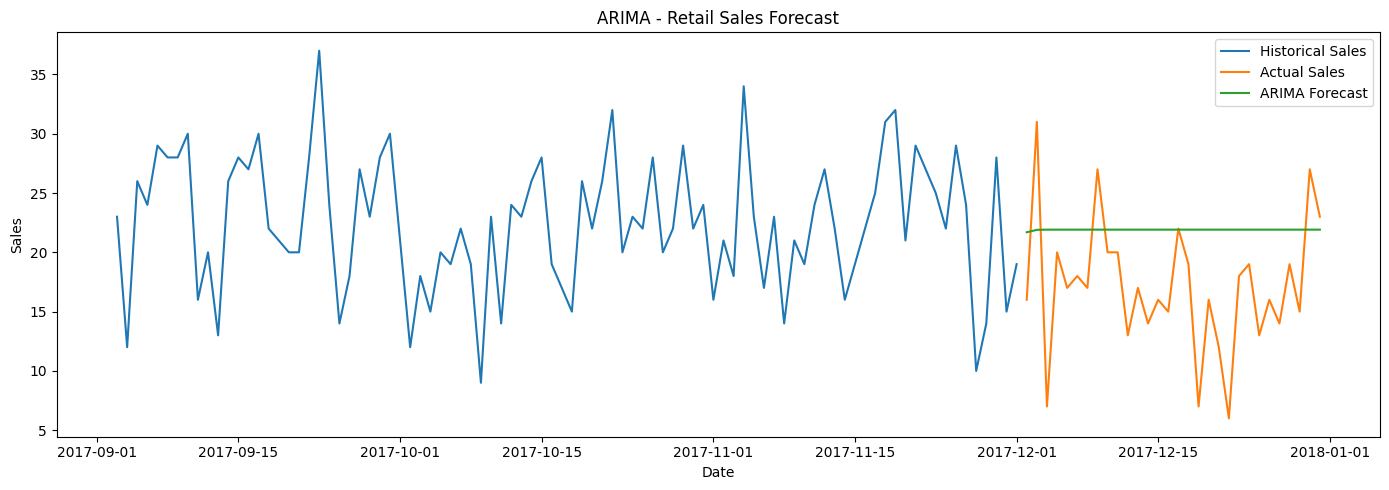

In [55]:
plt.figure(figsize=(14, 5))

plt.plot(
    arima_train.tail(90),
    label="Historical Sales"
)

plt.plot(
    arima_test,
    label="Actual Sales"
)

plt.plot(
    arima_predictions,
    label="ARIMA Forecast"
)

plt.title("ARIMA - Retail Sales Forecast")
plt.xlabel("Date")
plt.ylabel("Sales")

plt.legend()
plt.tight_layout()
plt.show()

In [56]:
def evaluate_model(actual, predicted):

    actual = np.asarray(actual)
    predicted = np.asarray(predicted)

    mae = mean_absolute_error(
        actual,
        predicted
    )

    rmse = np.sqrt(
        mean_squared_error(actual, predicted)
    )

    wape = (
        np.sum(np.abs(actual - predicted))
        / np.sum(np.abs(actual))
    ) * 100

    return {
        "MAE": mae,
        "RMSE": rmse,
        "WAPE": wape
    }


arima_results = evaluate_model(
    arima_test,
    arima_predictions
)

print("ARIMA Results:", arima_results)

ARIMA Results: {'MAE': 6.134775674274514, 'RMSE': np.float64(7.276369918010023), 'WAPE': np.float64(35.80608370199133)}


## Implement SARIMA

In [57]:
from statsmodels.tsa.statespace.sarimax import SARIMAX

sarima_model = SARIMAX(
    train_series,
    order=(1, 1, 1),
    seasonal_order=(1, 1, 1, 7),
    enforce_stationarity=False,
    enforce_invertibility=False
)

sarima_fitted = sarima_model.fit()

print(sarima_fitted.summary())

/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)


                                     SARIMAX Results                                     
Dep. Variable:                             sales   No. Observations:                 1796
Model:             SARIMAX(1, 1, 1)x(1, 1, 1, 7)   Log Likelihood               -5276.217
Date:                           Fri, 06 Nov 2026   AIC                          10562.434
Time:                                   15:01:22   BIC                          10589.853
Sample:                               01-01-2013   HQIC                         10572.562
                                    - 12-01-2017                                         
Covariance Type:                             opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.0191      0.027      0.711      0.477      -0.034       0.072
ma.L1         -0.9006      0.013    -71.765

### 30 days forecasting

In [58]:
sarima_predictions = sarima_fitted.forecast(
    steps=len(test_series)
)

sarima_predictions.index = test_series.index

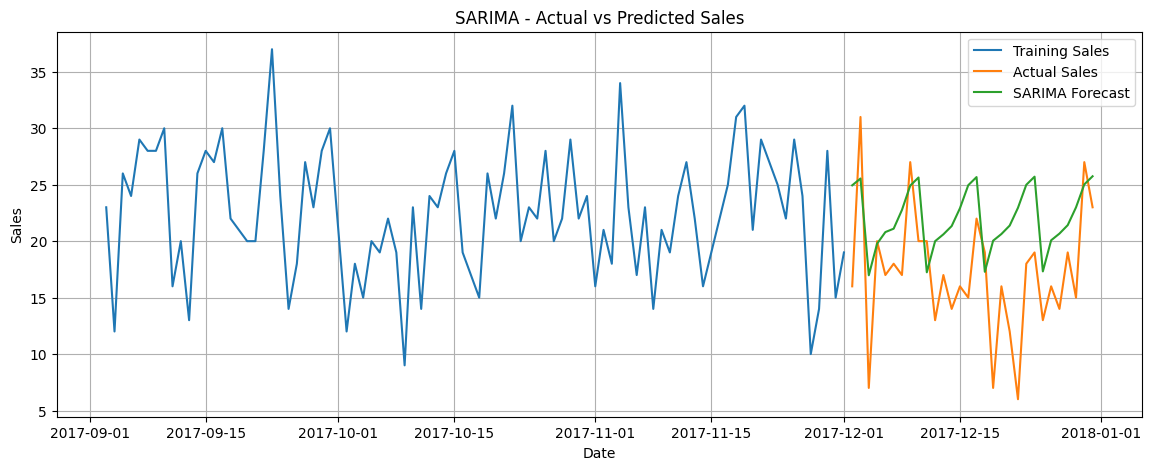

In [59]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 5))

plt.plot(
    train_series.index[-90:],
    train_series.tail(90),
    label="Training Sales"
)

plt.plot(
    test_series.index,
    test_series,
    label="Actual Sales"
)

plt.plot(
    sarima_predictions.index,
    sarima_predictions,
    label="SARIMA Forecast"
)

plt.title("SARIMA - Actual vs Predicted Sales")
plt.xlabel("Date")
plt.ylabel("Sales")
plt.legend()
plt.grid(True)
plt.show()

In [60]:
sarima_results = evaluate_model(
    test_series,
    sarima_predictions
)

print("SARIMA Results:")
print(sarima_results)

SARIMA Results:
{'MAE': 5.8619576132606666, 'RMSE': np.float64(6.859209839465708), 'WAPE': np.float64(34.21376038868093)}


In [61]:
comparison = pd.DataFrame(
    [arima_results, sarima_results],
    index=["ARIMA", "SARIMA"]
)

print(comparison)

             MAE     RMSE       WAPE
ARIMA   6.134776  7.27637  35.806084
SARIMA  5.861958  6.85921  34.213760


## XG Boost forecasting

In [62]:
xgb_train = features_df[
    features_df.index < cutoff_date
].copy()

X_train = xgb_train.drop(columns=["sales"])
y_train = xgb_train["sales"]

print("Training features:", X_train.shape)
print("Training target:", y_train.shape)

Training features: (1768, 13)
Training target: (1768,)


In [63]:
from xgboost import XGBRegressor

xgb_model = XGBRegressor(
    n_estimators=500,
    learning_rate=0.03,
    max_depth=5,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="reg:squarederror",
    random_state=42,
    n_jobs=-1
)

xgb_model.fit(X_train, y_train)

XGBRegressor(base_score=None, booster=None, callbacks=None,
             colsample_bylevel=None, colsample_bynode=None,
             colsample_bytree=0.8, device=None, early_stopping_rounds=None,
             enable_categorical=True, eval_metric=None, feature_types=None,
             feature_weights=None, gamma=None, grow_policy=None,
             importance_type=None, interaction_constraints=None,
             learning_rate=0.03, max_bin=None, max_cat_threshold=None,
             max_cat_to_onehot=None, max_delta_step=None, max_depth=5,
             max_leaves=None, min_child_weight=None, missing=nan,
             monotone_constraints=None, multi_strategy=None, n_estimators=500,
             n_jobs=-1, num_parallel_tree=None, ...)

### 30 days forecasting

In [64]:
import numpy as np
import pandas as pd

history = sales_series[
    sales_series.index < cutoff_date
].copy()

forecast_dates = test_series.index

xgb_forecasts = []

for current_date in forecast_dates:

    row = {}

    # Lag features
    for lag in [1, 7, 14, 28]:
        row[f"lag_{lag}"] = history.iloc[-lag]

    # Rolling features using past observations only
    row["rolling_mean_7"] = history.iloc[-7:].mean()
    row["rolling_mean_14"] = history.iloc[-14:].mean()
    row["rolling_mean_28"] = history.iloc[-28:].mean()
    row["rolling_std_7"] = history.iloc[-7:].std()

    # Calendar features
    row["day_of_week"] = current_date.dayofweek
    row["month"] = current_date.month
    row["day"] = current_date.day
    row["week_of_year"] = current_date.isocalendar().week
    row["is_weekend"] = int(current_date.dayofweek >= 5)

    # Maintain the same feature order used during training
    X_future = pd.DataFrame(
        [row],
        index=[current_date]
    )[X_train.columns]

    # Predict one day
    prediction = xgb_model.predict(X_future)[0]

    # Sales cannot be negative
    prediction = max(0, prediction)

    xgb_forecasts.append(prediction)

    # Add prediction to history for the next day's forecast
    history.loc[current_date] = prediction

xgb_predictions = pd.Series(
    xgb_forecasts,
    index=forecast_dates,
    name="XGBoost Forecast"
)

print(xgb_predictions)

date
2017-12-02    22.286657
2017-12-03    22.111803
2017-12-04    14.565008
2017-12-05    14.722851
2017-12-06    16.157328
2017-12-07    14.474684
2017-12-08    16.907370
2017-12-09    19.247272
2017-12-10    18.300211
2017-12-11    15.342432
2017-12-12    14.978644
2017-12-13    16.260262
2017-12-14    15.121611
2017-12-15    14.666453
2017-12-16    16.137184
2017-12-17    21.824976
2017-12-18    12.861913
2017-12-19    14.841825
2017-12-20    14.310954
2017-12-21    13.119585
2017-12-22    15.184012
2017-12-23    17.908773
2017-12-24    19.846523
2017-12-25    10.097832
2017-12-26    12.707048
2017-12-27    14.086390
2017-12-28    13.461879
2017-12-29    15.634023
2017-12-30    18.225096
2017-12-31    19.483126
Name: XGBoost Forecast, dtype: float32


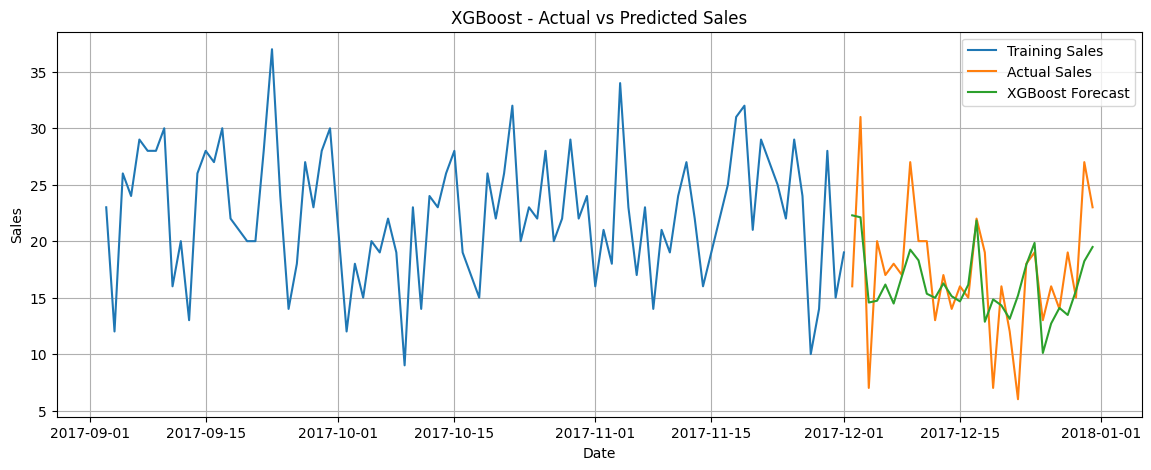

In [65]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 5))

plt.plot(
    train_series.index[-90:],
    train_series.tail(90),
    label="Training Sales"
)

plt.plot(
    test_series.index,
    test_series,
    label="Actual Sales"
)

plt.plot(
    xgb_predictions.index,
    xgb_predictions,
    label="XGBoost Forecast"
)

plt.title("XGBoost - Actual vs Predicted Sales")
plt.xlabel("Date")
plt.ylabel("Sales")
plt.legend()
plt.grid(True)
plt.show()

In [66]:
xgb_results = evaluate_model(
    test_series,
    xgb_predictions
)

print("XGBoost Results:")
print(xgb_results)

XGBoost Results:
{'MAE': 3.490973711013794, 'RMSE': np.float64(4.612725336623451), 'WAPE': np.float64(20.3753309954929)}


## Comparing all the 3 models

In [67]:
comparison = pd.DataFrame(
    [arima_results, sarima_results, xgb_results],
    index=["ARIMA", "SARIMA", "XGBoost"]
)

print(comparison.sort_values("WAPE"))

              MAE      RMSE       WAPE
XGBoost  3.490974  4.612725  20.375331
SARIMA   5.861958  6.859210  34.213760
ARIMA    6.134776  7.276370  35.806084
